# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Make Figure showing SOM training domain

**Notebook by Alice DuVivier - July 2026**

In [1]:
from glob import glob
import xarray as xr
from datetime import datetime
import time
import cftime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from datetime import timedelta

# Regridding
import xesmf as xe

## Section 1: Load grid files and create re-gridding weights

In [4]:
# set input directory
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/data_for_composites/'

### Load CAM elevation file

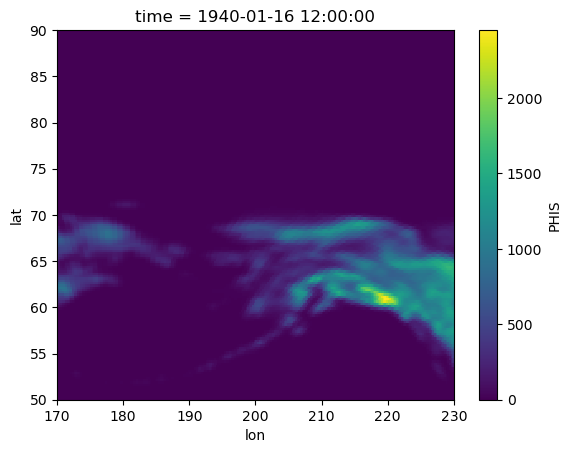

In [5]:
# load the land elevation file
fin = dir_in + 'MESACLIP_HGT_alaska.nc'
ds_hgt = xr.open_dataset(fin)

ds_hgt = ds_hgt.PHIS.isel(time=0)
ds_hgt.plot()

In [6]:
# reassign lon grid to be from -180 to 180 instead of 0-360
lon2 = np.where(ds_hgt.lon <180, ds_hgt.lon, ds_hgt.lon - 360)
ds_hgt['lon'] = lon2

In [7]:
# assign unit attributes
ds_hgt.lat.attrs['units'] = 'degrees_north'
ds_hgt.lon.attrs['units'] = 'degrees_east'

### Load EASE grid

In [8]:
# load the EASE grid
fin = dir_in + 'ease_nh50km_coordinates.nc'

ease_grid_full = xr.open_dataset(fin)
# replace missing values with nan
ease_grid_full = ease_grid_full.where(ease_grid_full != -999)

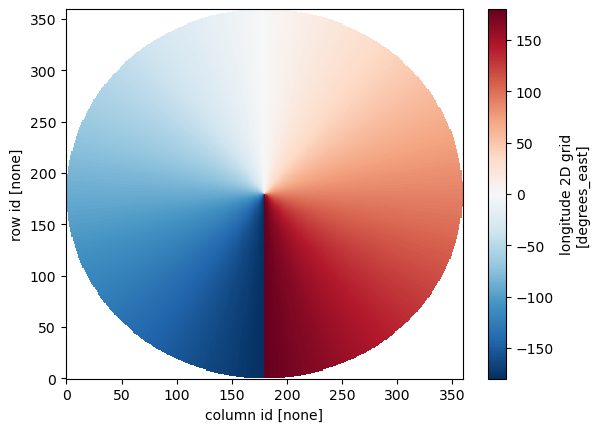

In [9]:
#ease_grid_full.lat2d.plot()
ease_grid_full.lon2d.plot()

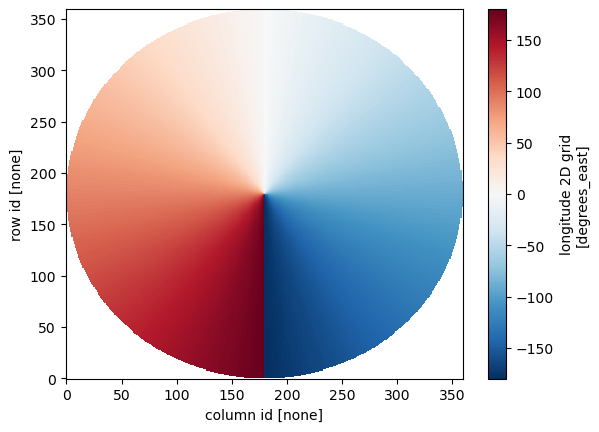

In [10]:
# this is a mirror image around -180/180, so need to reverse the column id values to match a normal map
test = -1 * ease_grid_full
#test.lon2d.plot()

# rewrite variable
ease_grid_full['lon2d'] = test['lon2d']
ease_grid_full.lon2d.plot()

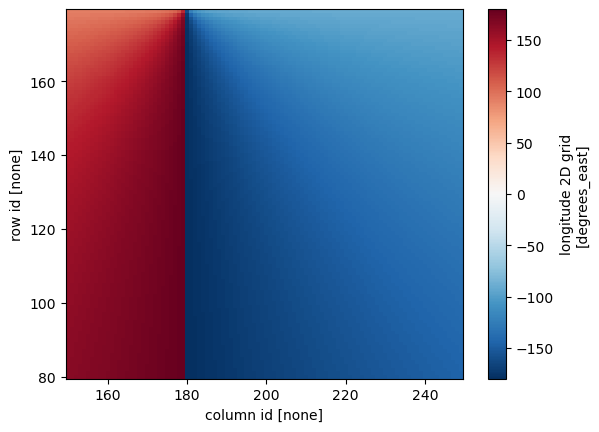

In [11]:
# subset ease grid
ease_grid_sub = ease_grid_full.isel(row=slice(80, 180),col=slice(150,250))
ease_grid_sub.lon2d.plot()

### Regrid

In [12]:
# set target and source grids
#lon_target, lat_target = ease_grid_full['lon2d'], ease_grid_full['lat2d']
lon_target, lat_target = ease_grid_sub['lon2d'], ease_grid_sub['lat2d']
lon_source, lat_source = ds_hgt['lon'], ds_hgt['lat']

In [13]:
# rename dimensions so that they make regridder happy
source_grid = {'lat': lat_source, 'lon': lon_source}
target_grid = {'lat': lat_target, 'lon': lon_target}

In [14]:
# actually regrid now
regridder = xe.Regridder(ds_hgt, target_grid, method='bilinear', unmapped_to_nan=True)
ds_hgt_regridded = regridder(ds_hgt)

/glade/u/apps/opt/miniforge/envs/npl-2026a/lib/python3.13/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not F_CONTIGUOUS. ' 'Will affect performance.')


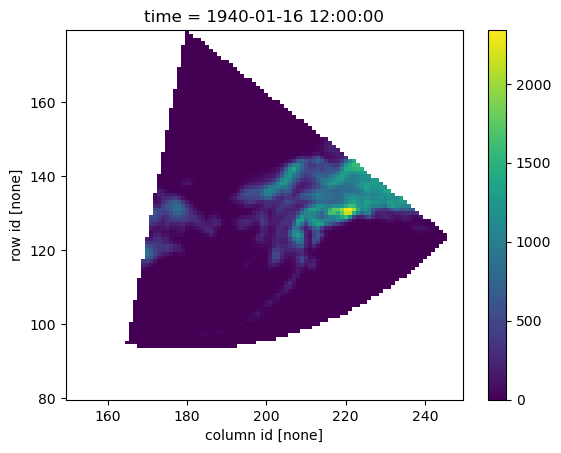

In [15]:
ds_hgt_regridded.plot()

## Section 2: Create Spatial Mask for Training Data
- Masks terrain above 500m - sea level pressure is weird over land so omit
- Crops to the training domain only (45-75N and 150-180W)

In [16]:
# make new array to match height
new = xr.ones_like(ds_hgt_regridded)
#new.plot()

In [17]:
ds_hgt_regridded

<xarray.DataArray (row: 100, col: 100)> Size: 80kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(100, 100))
Coordinates:
  * row      (row) float32 400B 80.0 81.0 82.0 83.0 ... 176.0 177.0 178.0 179.0
  * col      (col) float32 400B 150.0 151.0 152.0 153.0 ... 247.0 248.0 249.0
    time     object 8B 1940-01-16 12:00:00
    lat2d    (row, col) float32 40kB 41.65 41.79 41.92 ... 59.31 58.84 58.38
    lon2d    (row, col) float32 40kB 163.4 163.9 164.5 ... -90.64 -90.63 -90.62
Attributes:
    regrid_method:  bilinear

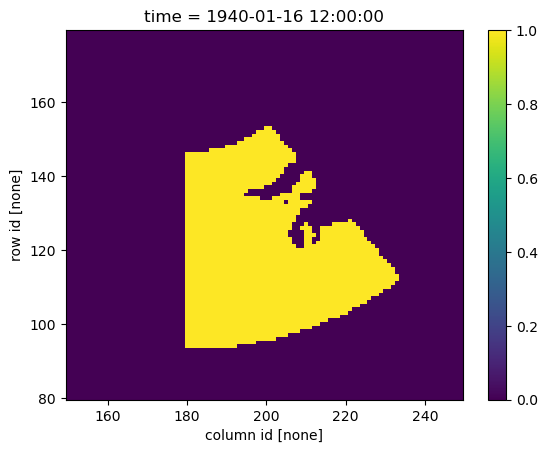

In [18]:
# need to use the intersection of masks for heights, lats, and lons we specify
ds_mask = xr.where((ds_hgt_regridded['lat2d']<75)&(ds_hgt_regridded['lat2d']>45)&(ds_hgt_regridded['lon2d']<-141)&(ds_hgt_regridded < 500),new,0)
ds_mask.plot()

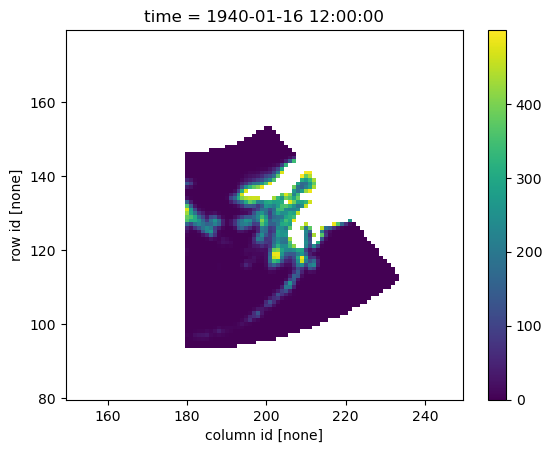

In [20]:
ds_hgt_plot = ds_hgt_regridded.where(ds_mask == 1)

ds_hgt_plot.plot()

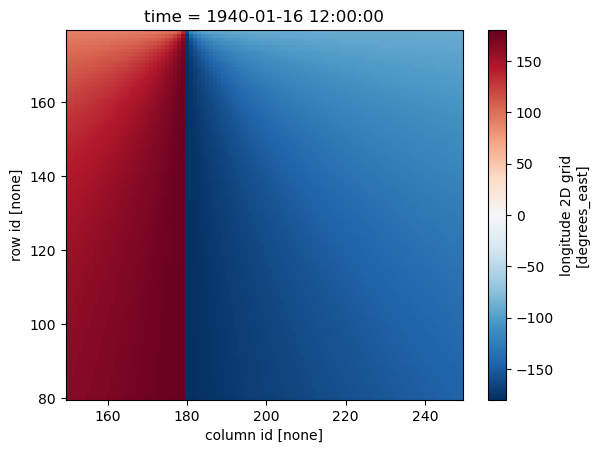

In [32]:
ds_hgt_plot.lon2d.plot()

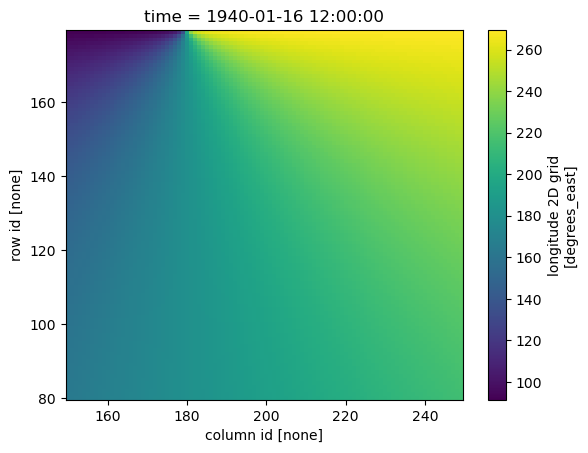

In [33]:
lon2d_new = ds_hgt_plot.lon2d.where(ds_hgt_plot.lon2d>0, ds_hgt_plot.lon2d+360)
lon2d_new.plot()

In [36]:
# reassign lon values
ds_hgt_plot["lon2d"] = lon2d_new

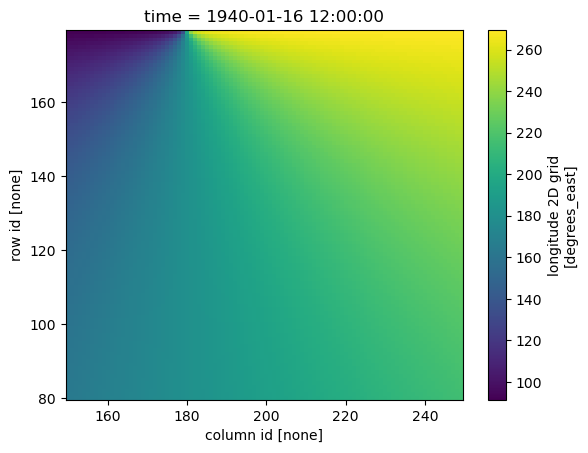

In [37]:
ds_hgt_plot.lon2d.plot()

## Plot composite maps of precip anomaly across lattice

In [67]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v1/'

In [22]:
## set colors
cmap_choice = plt.cm.get_cmap('viridis')

# set lat/lon bounds
lat_max = 72
lat_min = 52
lon_max = 218
lon_min = 182
lon_avg = 200

# set plotting info
vmin_in = 0
vmax_in = 500 
ticks_1 = [0,50,100,200,300,400,500]

/glade/derecho/scratch/duvivier/tmp/ipykernel_71125/1847196077.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_choice = plt.cm.get_cmap('viridis')


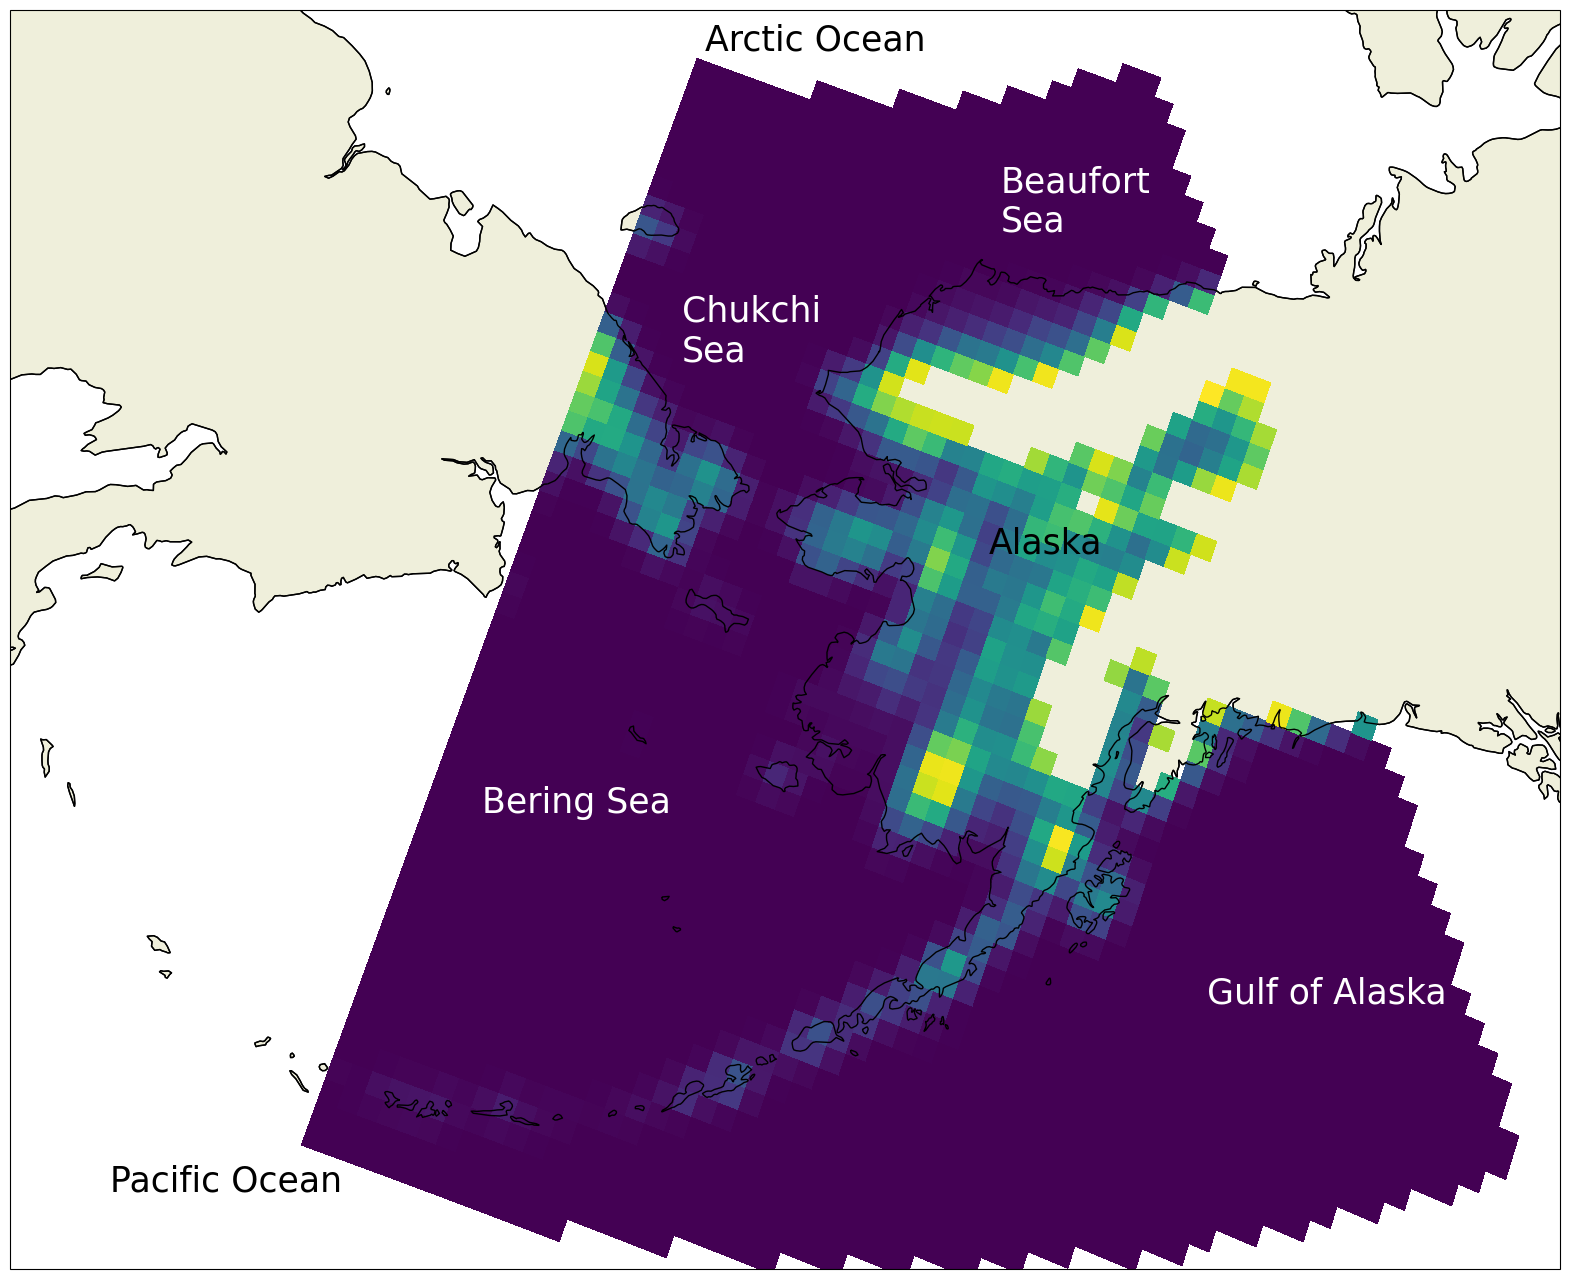

In [68]:
# create figure
fig = plt.figure(figsize=(20,20))
fout = 'training_domain_map'
     
# Make subplots - note it's nrow x ncol x index (starting upper left)
### First subplot: Alaska
ax = fig.add_subplot(1,1,1, projection=ccrs.NorthPolarStereo(central_longitude=200.0))
# map data
ax.add_feature(cfeature.LAND,zorder=0,edgecolor='k')
# contour data
ax.pcolor(ds_hgt_plot.lon2d,ds_hgt_plot.lat2d,ds_hgt_plot,
          vmin=vmin_in, vmax=vmax_in, cmap=cmap_choice,
          transform=ccrs.PlateCarree())
# modify plots
ax.set_extent([170, 220, 75, 50], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, edgecolor='k', alpha=1)
#fig.colorbar(ax, ticks=ticks_1[:],orientation='horizontal', extend='both')
# add place names text
ax.text(203.0, 65.0, s='Alaska',fontsize=25,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.text(175.0, 48.0, s='Pacific Ocean',fontsize=25,color='black',zorder=100,transform=ccrs.PlateCarree())
ax.text(210.0, 55.0, s='Gulf of Alaska',fontsize=25,color='white',zorder=100,transform=ccrs.PlateCarree())
ax.text(182.0, 58.0, s='Bering Sea',fontsize=25,color='white',zorder=100,transform=ccrs.PlateCarree())
ax.text(185.0, 68.5, s='Chukchi\nSea',fontsize=25,color='white',zorder=100,transform=ccrs.PlateCarree())
ax.text(205.0, 72.0, s='Beaufort\nSea',fontsize=25,color='white',zorder=100,transform=ccrs.PlateCarree())
ax.text(180.0, 75.2, s='Arctic Ocean',fontsize=25,color='black',zorder=100,transform=ccrs.PlateCarree())

# save figure
plt.savefig(dir_out + fout + '.png', bbox_inches='tight', dpi=200)